# Margin survival, execution mismatch and operations
Frozen study eed008040d6c6d18. Post-study evidence review, hypothetical fills.


In [1]:
from pathlib import Path
import os,sys,html
root=Path.cwd()
if not (root/'carry').exists():root=root.parent
os.chdir(root)
sys.path.insert(0,str(root))
def show_svg(svg):
    if '_emit_data' in globals():_emit_data({'image/svg+xml':svg})
    else:
        from IPython.display import display,SVG
        display(SVG(svg))
def show_table(headers,rows):
    markup='<table><thead><tr>'+''.join('<th>'+html.escape(str(v))+'</th>' for v in headers)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+html.escape(str(v))+'</td>' for v in row)+'</tr>' for row in rows)+'</tbody></table>'
    if '_emit_data' in globals():_emit_data({'text/html':markup})
    else:
        from IPython.display import display,HTML
        display(HTML(markup))


## Question
Can combined economic equity survive while isolated collateral fails, and what operational evidence remains missing? Inputs combine independent scenarios and frozen historical diagnostics. These calculations approximate margin and do not reconstruct venue liquidation.

In [2]:
import csv,json,math,statistics
from pathlib import Path
from carry.figures import lines,bars
from carry.engine import Config,replay,stress_case
from carry.run import sample,forecast_comparison,summarize,golden_case

def read_csv(name):
    with Path(name).open() as f:return list(csv.DictReader(f))


In [3]:
cases={'negative funding':{},'basis widening':{'perp_shock':.05},'joint 80% rally':{'spot_shock':.8,'perp_shock':.8},'half-filled spot':{'spot_fill':.5,'spot_shock':-.2,'perp_shock':-.2},'maintenance increase':{'maintenance_rate':.05,'perp_shock':.1},'collateral haircut':{'collateral_haircut':.5,'perp_shock':.1},'USDT depeg':{'stablecoin_usd':.9}}
results={name:stress_case(**params) for name,params in cases.items()}
show_table(['Scenario','Economic equity USDT','USD value','Margin buffer','Extra collateral'],[[name,*[round(r[k],2) for k in ('equity_usdt','equity_usd_after_depeg','margin_buffer_after_haircut','additional_collateral_required')]] for name,r in results.items()])
assert results['joint 80% rally']['equity_usdt']>99000
assert results['joint 80% rally']['margin_buffer_after_haircut']<0

Scenario,Economic equity USDT,USD value,Margin buffer,Extra collateral
negative funding,99840.49,99840.49,34301.51,0
basis widening,97087.74,97087.74,31518.51,0
joint 80% rally,99796.49,99796.49,-10226.49,10226.49
half-filled spot,105384.5,105384.5,45433.51,0
maintenance increase,94334.99,94334.99,26315.51,0
collateral haircut,94334.99,94334.99,11279.5,0
USDT depeg,99840.49,89856.45,34301.51,0


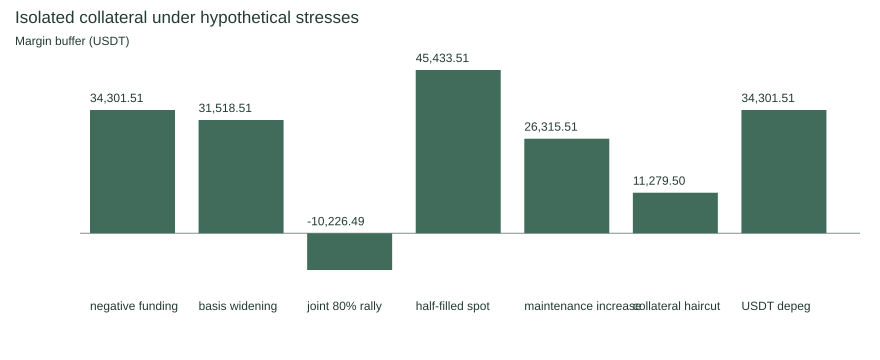

In [4]:
show_svg(bars('Isolated collateral under hypothetical stresses',list(results),[r['margin_buffer_after_haircut'] for r in results.values()],'Margin buffer (USDT)'))

In [5]:
rows=sample('BTCUSDT')[:15]
rows[1]['spot_fill']=.5;rows[1]['perp_fill']=0
ledger,fills=replay(rows,Config(),'continuous')
show_table(['Event','Spot units','Short units','Residual delta USDT','Margin buffer'],[[i,round(r['spot_qty'],4),round(r['perp_qty'],4),round(r['residual_delta_usdt'],2),round(r['margin_buffer'],2)] for i,r in enumerate(ledger[:6])])
assert ledger[1]['residual_delta_units']!=0

Event,Spot units,Short units,Residual delta USDT,Margin buffer
0,0.0,0.0,0.0,35000.0
1,0.4578,0.0,27193.6,35000.0
2,0.9156,-0.9156,0.0,34365.91
3,0.9156,-0.9156,0.0,33094.76
4,0.9156,-0.9156,0.0,33118.81
5,0.9156,-0.9156,0.0,32357.58


In [6]:
from carry.paper import step
row=dict(timestamp='2026-11-24T00:00:00Z',symbol='BTCUSDT',spot=100,perp=100,mark=100,funding=.001,observed_ms=1000000)
funds=[dict(fundingTime=900000,fundingRate='.001',markPrice='100')]
initial=step(None,row,funds)
assert initial['receipt']['funding_total']==0 and initial['receipt']['modeled_fills']==0
show_table(['Paper initialization check','Result'],[['Old funding claimed',initial['receipt']['funding_total']],['Immediate fills',initial['receipt']['modeled_fills']],['State','Flat; target eligible on later observation']])

Paper initialization check,Result
Old funding claimed,0.0
Immediate fills,0
State,Flat; target eligible on later observation


## Incident and recovery
The hosted paper run returned HTTP 451 from Binance futures. Scheduling is intentionally disabled; no successful forward state or track record is claimed. Do not substitute assumed observations for failed collection. A permitted environment must be verified before scheduling; preserve state, inspect funding cadence and keep incident receipts.

## Conclusion and artifacts
Delta neutrality does not make the position risk-free. Separate margin, basis, funding, partial fills, collateral eligibility and currency translation matter. The public workbook Scenario exposes these mechanisms. Sources: `stress_case`, frozen margin diagnostics, `docs/RUNBOOK.md` and the retained failed workflow link in `docs/RELEASE_NOTES.md`.